# Predicting 30-Day Hospital Readmission in Diabetic Patients
### Traditional ML (scikit-learn) vs Deep Learning (TensorFlow/Keras)
**Dataset:** Diabetes 130-US Hospitals for Years 1999-2008 (UCI ML Repository, id 296), 101,766 encounters, 50 raw features.

**Problem statement.** Hospital readmissions within 30 days are costly and are a recognised quality-of-care indicator.
Given information available at discharge (demographics, prior utilisation, diagnoses, lab results, medications),
can we predict whether a diabetic patient will be **readmitted in under 30 days**?

**Task:** binary classification, `1 = readmitted <30 days`, `0 = readmitted >30 days or never`.
This is a heavily imbalanced problem (about 9-11% positives), so accuracy is a misleading metric. We report ROC-AUC, PR-AUC, precision, recall and F-scores.

**Notebook map**
1. Setup and data loading
2. Exploratory data analysis (EDA)
3. Cleaning
4. Feature engineering
5. Train/test split and preprocessing pipeline
6. Traditional ML baselines (with a feature-engineering ablation)
7. Hyperparameter tuning
8. Learning curves
9. Threshold selection and test evaluation of ML models
10. Deep learning with `tf.data` (Sequential and Functional API)
11. Final comparison, ROC/PR curves, confusion matrices
12. Error analysis and feature importance
13. Saving artefacts

## 1. Setup and data loading
We fix random seeds for reproducibility. The raw CSV is downloaded from the UCI repository the first time the notebook runs.
**Do not commit the CSV to GitHub** (it is in `.gitignore`); it goes in your Google Drive folder instead.

> If the download is blocked, download the zip manually from UCI, extract `diabetic_data.csv` next to this notebook (or into Colab's file panel) and re-run.

In [6]:
import os, io, zipfile, random, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__)

DATA_URL = 'https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip'
CSV = 'diabetic_data.csv'
if not os.path.exists(CSV):
    raw = urllib.request.urlopen(DATA_URL).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        z.extract('diabetic_data.csv'); z.extract('IDs_mapping.csv')

# '?' is the dataset's marker for missing values
df_raw = pd.read_csv(CSV, na_values='?')
print(df_raw.shape)
df_raw.head()

TensorFlow 2.21.0
(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 2. Exploratory data analysis
Goals: confirm the size requirement (>= 20,000 rows), understand missingness, look at the class balance, and spot data-quality issues.
Things to write about in the report: class imbalance, the near-empty `weight` column, repeated encounters per patient, and patients who died or went to hospice.

In [7]:
print('Rows x columns:', df_raw.shape, '(requirement: >= 20,000 rows)')
print('Unique patients:', df_raw['patient_nbr'].nunique())

missing = (df_raw.isna().mean() * 100).sort_values(ascending=False)
print('\nColumns with missing values (%):')
print(missing[missing > 0].round(1))

print('\nOriginal 3-class target:')
print(df_raw['readmitted'].value_counts())
print(df_raw['readmitted'].value_counts(normalize=True).round(3))

Rows x columns: (101766, 50) (requirement: >= 20,000 rows)
Unique patients: 71518

Columns with missing values (%):
weight               96.9
max_glu_serum        94.7
A1Cresult            83.3
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
diag_1                0.0
dtype: float64

Original 3-class target:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64


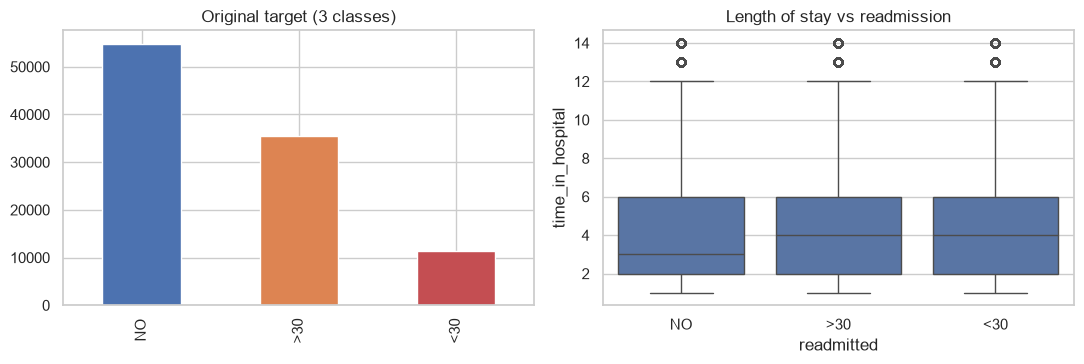

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df_raw['readmitted'].value_counts().plot.bar(ax=ax[0], color=['#4c72b0', '#dd8452', '#c44e52'])
ax[0].set_title('Original target (3 classes)'); ax[0].set_xlabel('')
sns.boxplot(data=df_raw, x='readmitted', y='time_in_hospital', ax=ax[1], order=['NO', '>30', '<30'])
ax[1].set_title('Length of stay vs readmission')
plt.tight_layout(); plt.show()

## 3. Cleaning
Decisions (each should be justified in the Methodology section of your report):

* **Binary target:** `readmitted == '<30'` becomes 1, everything else 0. This is the clinically relevant, standard formulation.
* **Remove patients who died or went to hospice** (discharge codes 11, 13, 14, 19, 20, 21): they cannot be readmitted, so keeping them corrupts the labels.
* **Remove `Unknown/Invalid` gender** (3 rows).
* **Keep one encounter per patient** (the earliest by `encounter_id`). Many patients appear several times; if the same patient lands in both train and test, performance is inflated (data leakage). Encounter IDs are assumed to be chronological, which is the usual assumption for this dataset.
* **Drop `weight`** (about 97% missing), **identifiers**, and **constant columns**.
* Remaining missing categorical values become an explicit `'Missing'` category (missingness itself can be informative, e.g. for `medical_specialty`).

In [9]:
df = df_raw.copy()

# 1. remove expired / hospice discharges
EXPIRED_HOSPICE = [11, 13, 14, 19, 20, 21]
df = df[~df['discharge_disposition_id'].isin(EXPIRED_HOSPICE)]

# 2. invalid gender
df = df[df['gender'] != 'Unknown/Invalid']

# 3. one encounter per patient (earliest)
df = df.sort_values('encounter_id').drop_duplicates('patient_nbr', keep='first')

# 4. binary target
df['target'] = (df['readmitted'] == '<30').astype(int)

# 5. drop unusable columns
df = df.drop(columns=['encounter_id', 'patient_nbr', 'weight', 'readmitted'])
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print('Constant columns dropped:', const_cols)
df = df.drop(columns=const_cols)

# ID-like columns are categories, not quantities
ID_COLS = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
df[ID_COLS] = df[ID_COLS].astype(str)

print('Shape after cleaning:', df.shape)
print('Positive rate (<30 days): %.3f' % df['target'].mean())

Constant columns dropped: ['examide', 'citoglipton', 'glimepiride-pioglitazone']
Shape after cleaning: (69987, 44)
Positive rate (<30 days): 0.090


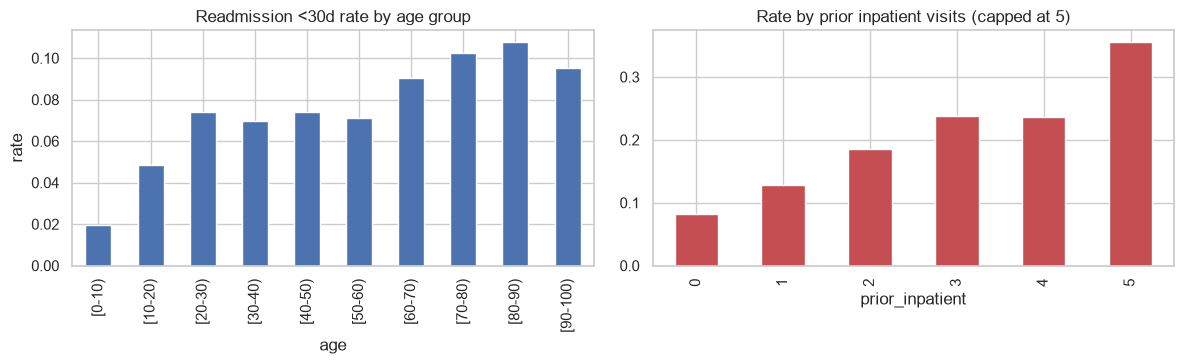

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
df.groupby('age')['target'].mean().plot.bar(ax=ax[0], color='#4c72b0')
ax[0].set_title('Readmission <30d rate by age group'); ax[0].set_ylabel('rate')
(df.assign(prior_inpatient=df['number_inpatient'].clip(upper=5))
   .groupby('prior_inpatient')['target'].mean().plot.bar(ax=ax[1], color='#c44e52'))
ax[1].set_title('Rate by prior inpatient visits (capped at 5)')
plt.tight_layout(); plt.show()

## 4. Feature engineering
New features (all computed from the same row only, so no leakage):

| Feature | Idea |
|---|---|
| `diag_1_grp`, `diag_2_grp`, `diag_3_grp` | ~700 raw ICD-9 codes collapsed into 9 clinical groups (Strack et al., 2014) |
| `age_num` | age bracket converted to its midpoint |
| `total_prior_visits` | outpatient + emergency + inpatient visits in the previous year |
| `n_med_changes` | number of drugs whose dose went Up/Down |
| `n_meds_active` | number of diabetes drugs the patient is on |
| `meds_per_day`, `lab_per_day` | intensity of treatment relative to length of stay |

We keep two feature sets, **base** (raw columns only) and **engineered**, so Section 6 can run an ablation showing whether the engineering actually helps.

In [11]:
MED_COLS_ALL = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide',
    'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol',
    'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin',
    'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
MED_COLS = [c for c in MED_COLS_ALL if c in df.columns]

def icd9_group(code):
    if pd.isna(code): return 'Missing'
    c = str(code)
    if c.startswith(('V', 'E')): return 'Other'
    try: v = float(c)
    except ValueError: return 'Other'
    if 250 <= v < 251: return 'Diabetes'
    if 390 <= v <= 459 or v == 785: return 'Circulatory'
    if 460 <= v <= 519 or v == 786: return 'Respiratory'
    if 520 <= v <= 579 or v == 787: return 'Digestive'
    if 800 <= v <= 999: return 'Injury'
    if 710 <= v <= 739: return 'Musculoskeletal'
    if 580 <= v <= 629 or v == 788: return 'Genitourinary'
    if 140 <= v <= 239: return 'Neoplasms'
    return 'Other'

for i in (1, 2, 3):
    df[f'diag_{i}_grp'] = df[f'diag_{i}'].apply(icd9_group)
df = df.drop(columns=['diag_1', 'diag_2', 'diag_3'])

df['age_num'] = df['age'].str.extract(r'\[(\d+)-')[0].astype(int) + 5
df['total_prior_visits'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient']
df['n_med_changes'] = df[MED_COLS].isin(['Up', 'Down']).sum(axis=1)
df['n_meds_active'] = (df[MED_COLS] != 'No').sum(axis=1)
df['meds_per_day'] = df['num_medications'] / df['time_in_hospital']
df['lab_per_day'] = df['num_lab_procedures'] / df['time_in_hospital']

# remaining missing categoricals -> explicit category
obj_cols = df.select_dtypes('object').columns
df[obj_cols] = df[obj_cols].fillna('Missing')

NUM_BASE = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
CAT_BASE = ['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
            'payer_code', 'medical_specialty', 'max_glu_serum', 'A1Cresult', 'change', 'diabetesMed'] + MED_COLS
NUM_ENG = NUM_BASE + ['age_num', 'total_prior_visits', 'n_med_changes', 'n_meds_active', 'meds_per_day', 'lab_per_day']
CAT_ENG = CAT_BASE + ['diag_1_grp', 'diag_2_grp', 'diag_3_grp']
FEATURE_SETS = {'base': (NUM_BASE, CAT_BASE), 'engineered': (NUM_ENG, CAT_ENG)}

print({k: len(v[0]) + len(v[1]) for k, v in FEATURE_SETS.items()}, 'features per set')
df.head()

{'base': 40, 'engineered': 49} features per set


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,insulin,glyburide-metformin,glipizide-metformin,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,target,diag_1_grp,diag_2_grp,diag_3_grp,age_num,total_prior_visits,n_med_changes,n_meds_active,meds_per_day,lab_per_day
8,Caucasian,Female,[80-90),2,1,4,13,Missing,Missing,68,2,28,0,0,0,8,Missing,Missing,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,Steady,No,No,No,No,Ch,Yes,0,Circulatory,Circulatory,Other,85,0,0,2,2.153846,5.230769
9,Caucasian,Female,[90-100),3,3,4,12,Missing,InternalMedicine,33,3,18,0,0,0,8,Missing,Missing,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,Steady,No,No,No,No,Ch,Yes,0,Circulatory,Neoplasms,Respiratory,95,0,0,2,1.500000,2.750000
4,Caucasian,Male,[40-50),1,1,7,1,Missing,Missing,51,0,8,0,0,0,5,Missing,Missing,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,Steady,No,No,No,No,Ch,Yes,0,Neoplasms,Neoplasms,Diabetes,45,0,0,2,8.000000,51.000000
10,AfricanAmerican,Female,[40-50),1,1,7,9,Missing,Missing,47,2,17,0,0,0,9,Missing,Missing,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Yes,0,Diabetes,Circulatory,Injury,45,0,0,1,1.888889,5.222222
5,Caucasian,Male,[50-60),2,1,2,3,Missing,Missing,31,6,16,0,0,0,9,Missing,Missing,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Yes,0,Circulatory,Circulatory,Diabetes,55,0,0,1,5.333333,10.333333


## 5. Train/test split and preprocessing pipeline
We hold out **20% as a final test set** that is only touched at the very end. All model selection uses cross-validation on the training portion.
The split is **stratified** to preserve the rare-class ratio.

Preprocessing lives inside a scikit-learn `Pipeline`/`ColumnTransformer`, so imputation, scaling and one-hot encoding are fitted on training folds only (no leakage). Rare categories (<100 occurrences) are merged into an "infrequent" bucket.

In [12]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone

X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', X_train.shape, ' positives: %.3f' % y_train.mean())
print('Test: ', X_test.shape,  ' positives: %.3f' % y_test.mean())

def make_pre(num_cols, cat_cols):
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=100, sparse_output=False), cat_cols),
    ])

def make_pipe(clf, fs='engineered'):
    num, cat = FEATURE_SETS[fs]
    return Pipeline([('pre', make_pre(num, cat)), ('clf', clf)])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

Train: (55989, 49)  positives: 0.090
Test:  (13998, 49)  positives: 0.090


## 6. Traditional ML baselines and feature-engineering ablation
Four algorithm families: Logistic Regression, a (calibrated) Linear SVM, Random Forest and Histogram Gradient Boosting. All use class weighting to counter the imbalance.
Each model is evaluated with 3-fold CV on **both** feature sets. If `engineered` beats `base`, you have evidence for your feature-engineering claim.

We also include a kernel (RBF) SVM on a 12,000-row subsample, because an RBF SVM on ~56,000 rows is impractically slow. Mention this limitation in the report.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def get_models():
    return {
        'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced', C=1.0),
        'LinearSVM': CalibratedClassifierCV(LinearSVC(class_weight='balanced', C=0.05, dual=False), cv=3),
        'RandomForest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features='sqrt',
                                               class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
        'HistGradientBoosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED),
    }

scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}
rows = []
for fs in FEATURE_SETS:
    for name, clf in get_models().items():
        res = cross_validate(make_pipe(clf, fs), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
        rows.append({'features': fs, 'model': name,
                     'roc_auc': res['test_roc_auc'].mean(), 'roc_auc_std': res['test_roc_auc'].std(),
                     'pr_auc': res['test_pr_auc'].mean()})
        print(f'{fs:11s} {name:22s} ROC-AUC={rows[-1]["roc_auc"]:.4f}  PR-AUC={rows[-1]["pr_auc"]:.4f}')

# RBF-SVM on a stratified subsample
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=12000, stratify=y_train, random_state=SEED)
res = cross_validate(make_pipe(SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced'), 'engineered'),
                     X_sub, y_sub, cv=cv, scoring=scoring, n_jobs=-1)
rows.append({'features': 'engineered', 'model': 'RBF-SVM (12k subsample)',
             'roc_auc': res['test_roc_auc'].mean(), 'roc_auc_std': res['test_roc_auc'].std(),
             'pr_auc': res['test_pr_auc'].mean()})

baseline_df = pd.DataFrame(rows).round(4)
baseline_df

base        LogisticRegression     ROC-AUC=0.6435  PR-AUC=0.1631
base        LinearSVM              ROC-AUC=0.6437  PR-AUC=0.1627
base        RandomForest           ROC-AUC=0.6490  PR-AUC=0.1695
base        HistGradientBoosting   ROC-AUC=0.6475  PR-AUC=0.1689
engineered  LogisticRegression     ROC-AUC=0.6454  PR-AUC=0.1650
engineered  LinearSVM              ROC-AUC=0.6458  PR-AUC=0.1644
engineered  RandomForest           ROC-AUC=0.6525  PR-AUC=0.1703
engineered  HistGradientBoosting   ROC-AUC=0.6533  PR-AUC=0.1665


,features,model,roc_auc,roc_auc_std,pr_auc
0,base,LogisticRegression,0.6435,0.0066,0.1631
1,base,LinearSVM,0.6437,0.0065,0.1627
2,base,RandomForest,0.6490,0.0056,0.1695
3,base,HistGradientBoosting,0.6475,0.0063,0.1689
4,engineered,LogisticRegression,0.6454,0.0056,0.1650
5,engineered,LinearSVM,0.6458,0.0056,0.1644
6,engineered,RandomForest,0.6525,0.0056,0.1703
7,engineered,HistGradientBoosting,0.6533,0.0062,0.1665
8,engineered,RBF-SVM (12k subsample),0.6155,0.0119,0.1371


features,base,engineered,gain_from_engineering
model,,,
HistGradientBoosting,0.6475,0.6533,0.0058
LinearSVM,0.6437,0.6458,0.0021
LogisticRegression,0.6435,0.6454,0.0019
RBF-SVM (12k subsample),NaN,0.6155,NaN
RandomForest,0.6490,0.6525,0.0035


The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


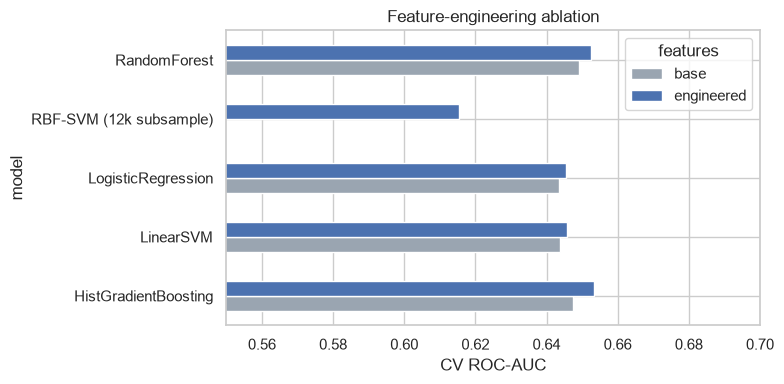

In [17]:
pivot = baseline_df.pivot(index='model', columns='features', values='roc_auc')
pivot['gain_from_engineering'] = pivot['engineered'] - pivot['base']
display(pivot.round(4))
pivot[['base', 'engineered']].plot.barh(figsize=(8, 4), color=['#9aa5b1', '#4c72b0'])
plt.xlim(0.55, 0.7); plt.xlabel('CV ROC-AUC'); plt.title('Feature-engineering ablation'); plt.tight_layout(); plt.show()

**Interpretation.** On the engineered features, untuned histogram gradient boosting leads (CV ROC-AUC 0.6533), just ahead of the random forest (0.6525), the linear SVM (0.6458) and logistic regression (0.6454). Feature engineering raises ROC-AUC for every full-data model, by 0.0019 (logistic regression) to 0.0058 (gradient boosting). The mean gain is 0.0033, similar to the fold standard deviation of about 0.006, so the improvement is consistent but small. The RBF SVM result (0.6155 on 12,000 rows) is not comparable with the models trained on the full training set.


## 7. Hyperparameter tuning
`RandomizedSearchCV` explores a defined search space for Logistic Regression, Random Forest and Gradient Boosting (3-fold CV, ROC-AUC objective). The best pipeline is refitted on the full training set.
In the report, include the search spaces in a table and discuss which hyperparameters mattered most (see `cv_results_`).

In [22]:
from sklearn.model_selection import RandomizedSearchCV

spaces = {
    'LogisticRegression': (
        LogisticRegression(max_iter=2000, class_weight='balanced'),
        {'clf__C': [0.001, 0.01, 0.1, 1, 10]}, 5),
    'RandomForest': (
        RandomForestClassifier(class_weight='balanced_subsample', n_jobs=1, random_state=SEED),
        {'clf__n_estimators': [200, 300, 500], 'clf__max_depth': [8, 12, 16, None],
         'clf__min_samples_leaf': [3, 5, 10, 20], 'clf__max_features': ['sqrt', 0.3]}, 12),
    'HistGradientBoosting': (
        HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED),
        {'clf__learning_rate': [0.02, 0.05, 0.1], 'clf__max_depth': [3, 5, None],
         'clf__max_leaf_nodes': [15, 31, 63], 'clf__min_samples_leaf': [20, 50, 100],
         'clf__l2_regularization': [0, 1, 10], 'clf__max_iter': [200, 400]}, 12),
}

searches = {}
for name, (est, space, n_iter) in spaces.items():
    s = RandomizedSearchCV(make_pipe(est), space, n_iter=n_iter, scoring='roc_auc', cv=cv,
                           n_jobs=-1, random_state=SEED, refit=True, verbose=0)
    s.fit(X_train, y_train)
    searches[name] = s
    print(f'{name:22s} best CV ROC-AUC = {s.best_score_:.4f}  params = {s.best_params_}')

best_name = max(searches, key=lambda k: searches[k].best_score_)
best_ml = searches[best_name].best_estimator_
print('\nBest traditional model (by CV):', best_name)

LogisticRegression     best CV ROC-AUC = 0.6471  params = {'clf__C': 0.01}
RandomForest           best CV ROC-AUC = 0.6552  params = {'clf__n_estimators': 500, 'clf__min_samples_leaf': 10, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
HistGradientBoosting   best CV ROC-AUC = 0.6539  params = {'clf__min_samples_leaf': 100, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 400, 'clf__max_depth': None, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0}

Best traditional model (by CV): RandomForest


## 8. Learning curves
A learning curve plots training and validation score against training-set size.

* **Large gap** between the curves means overfitting (high variance): more data, regularisation or a simpler model helps.
* **Both curves low and converged** means underfitting (high bias): need richer features or a more flexible model.
* **Validation curve still rising** means more data would help.

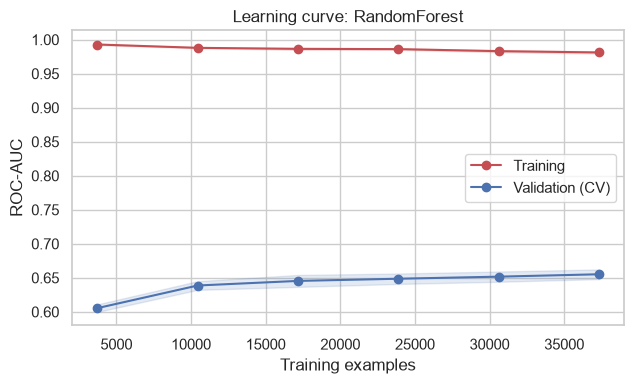

In [23]:
from sklearn.model_selection import learning_curve

sizes, tr_sc, va_sc = learning_curve(clone(best_ml), X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 6),
                                     cv=cv, scoring='roc_auc', n_jobs=-1, random_state=SEED)
plt.figure(figsize=(6.5, 4))
for sc, lab, col in [(tr_sc, 'Training', '#c44e52'), (va_sc, 'Validation (CV)', '#4c72b0')]:
    plt.plot(sizes, sc.mean(1), 'o-', label=lab, color=col)
    plt.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), alpha=0.15, color=col)
plt.xlabel('Training examples'); plt.ylabel('ROC-AUC'); plt.title(f'Learning curve: {best_name}')
plt.legend(); plt.tight_layout(); plt.show()

**Interpretation.** Training ROC-AUC stays near 0.98-0.99. Cross-validated ROC-AUC rises from about 0.61 to about 0.65 and then flattens. The gap of roughly 0.33 shows that the forest fits each training fold very closely, while the flat validation curve means more rows of the same features would add little. The horizontal axis stops near 37,000 because each cross-validation fold trains on about two-thirds of the 55,989 training rows.


## 9. Threshold selection and test-set evaluation (ML)
The default 0.5 threshold is poor for an imbalanced target. We choose the threshold that maximises **F2** (recall weighted twice as much as precision, since missing a high-risk patient is costlier than an extra follow-up call).
The threshold is chosen on **out-of-fold training predictions**, never on the test set.
Change `BETA` to 1 for F1 if you prefer a balanced trade-off.

In [24]:
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score, fbeta_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

BETA = 2.0
def best_threshold(y_true, proba, beta=BETA):
    p, r, t = precision_recall_curve(y_true, proba)
    f = (1 + beta**2) * p * r / np.maximum(beta**2 * p + r, 1e-12)
    return t[np.nanargmax(f[:-1])]

def summarise(name, y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {'model': name, 'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'threshold': thr, 'precision': precision_score(y_true, pred), 'recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred), 'F2': fbeta_score(y_true, pred, beta=2)}

test_probs, thresholds, summary_rows = {}, {}, []
for name, s in searches.items():
    oof = cross_val_predict(clone(s.best_estimator_), X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    thresholds[name] = best_threshold(y_train, oof)
    test_probs[name] = s.best_estimator_.predict_proba(X_test)[:, 1]
    summary_rows.append(summarise(name + ' (tuned)', y_test, test_probs[name], thresholds[name]))

ml_summary = pd.DataFrame(summary_rows).set_index('model').round(4)
ml_summary

,ROC-AUC,PR-AUC,threshold,precision,recall,F1,F2
model,,,,,,,
LogisticRegression (tuned),0.6486,0.1686,0.4232,0.1143,0.7621,0.1987,0.3571
RandomForest (tuned),0.6564,0.1792,0.3224,0.1240,0.6794,0.2098,0.3584
HistGradientBoosting (tuned),0.6504,0.1832,0.4367,0.1168,0.7001,0.2002,0.3502


In [25]:
print(f'Classification report, {best_name} (threshold = {thresholds[best_name]:.3f})')
pred_best = (test_probs[best_name] >= thresholds[best_name]).astype(int)
print(classification_report(y_test, pred_best, target_names=['Not <30d', 'Readmitted <30d']))

def bootstrap_ci(y_true, proba, n=500, seed=SEED):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() != y_true[idx].max():
            vals.append(roc_auc_score(y_true[idx], proba[idx]))
    return np.percentile(vals, [2.5, 97.5])
print('95%% bootstrap CI for ROC-AUC: [%.4f, %.4f]' % tuple(bootstrap_ci(y_test, test_probs[best_name])))

Classification report, RandomForest (threshold = 0.322)
                 precision    recall  f1-score   support

       Not <30d       0.94      0.53      0.68     12741
Readmitted <30d       0.12      0.68      0.21      1257

       accuracy                           0.54     13998
      macro avg       0.53      0.60      0.44     13998
   weighted avg       0.87      0.54      0.63     13998

95% bootstrap CI for ROC-AUC: [0.6400, 0.6734]


**Interpretation.** The tuned random forest is the best traditional model on the test set: ROC-AUC 0.6564 (95% bootstrap CI 0.6400-0.6734), PR-AUC 0.1792. At the F2 threshold of 0.322 it recalls 67.9% of early readmissions with precision of only 12.4%. Accuracy is 0.54 and is not a useful summary, because the positive class is about 9% of encounters.


## 10. Deep learning with TensorFlow/Keras and `tf.data`
**Input pipeline.** We split the training set again into train (85%) and validation (15%), fit the preprocessor on the sub-train only, and feed the arrays through `tf.data.Dataset` (shuffle, batch, prefetch).

**Imbalance.** Class weights are passed to `fit`.

**Architectures.**
* *Sequential API:* stacked Dense, BatchNorm and Dropout blocks.
* *Functional API:* a residual MLP (skip connections around each block), which cannot be expressed in `Sequential`.

**Tuning.** A small manual search over width, depth, dropout, L2 and learning rate, using early stopping on validation AUC. We keep the best model and plot its learning curves.

In [26]:
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

NUM, CAT = FEATURE_SETS['engineered']
X_tr2, X_va, y_tr2, y_va = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)

dl_pre = make_pre(NUM, CAT)
Xtr = dl_pre.fit_transform(X_tr2).astype('float32')
Xva = dl_pre.transform(X_va).astype('float32')
Xte = dl_pre.transform(X_test).astype('float32')
ytr, yva, yte = y_tr2.values.astype('float32'), y_va.values.astype('float32'), y_test.values.astype('float32')
print('Feature matrix shape:', Xtr.shape)

BATCH = 256
def make_ds(X_, y_, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X_, y_))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X_), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(Xtr, ytr, True), make_ds(Xva, yva), make_ds(Xte, yte)

cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=ytr)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print('Class weights:', class_weight)

Feature matrix shape: (47590, 195)
Class weights: {0: 0.5493351186628498, 1: 5.567384183434721}


In [27]:
def compile_model(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc'), keras.metrics.AUC(name='pr_auc', curve='PR'),
                       keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')])
    return m

def build_sequential(input_dim, units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3):
    reg = keras.regularizers.l2(l2)
    m = keras.Sequential([keras.Input(shape=(input_dim,))], name='sequential_mlp')
    for u in units:
        m.add(layers.Dense(u, activation='relu', kernel_regularizer=reg))
        m.add(layers.BatchNormalization())
        m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation='sigmoid'))
    return compile_model(m, lr)

def build_functional(input_dim, width=128, n_blocks=2, dropout=0.3, l2=1e-4, lr=1e-3):
    reg = keras.regularizers.l2(l2)
    inp = keras.Input(shape=(input_dim,))
    x = layers.Dense(width, activation='relu', kernel_regularizer=reg)(inp)
    for _ in range(n_blocks):
        h = layers.Dense(width, activation='relu', kernel_regularizer=reg)(x)
        h = layers.BatchNormalization()(h)
        h = layers.Dropout(dropout)(h)
        x = layers.Add()([x, h])                      # residual connection
    out = layers.Dense(1, activation='sigmoid')(x)
    return compile_model(keras.Model(inp, out, name='residual_mlp'), lr)

def train_dl(builder, params, epochs=60):
    keras.backend.clear_session()
    model = builder(input_dim=Xtr.shape[1], **params)
    cbs = [keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=8, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=3, min_lr=1e-5)]
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, class_weight=class_weight,
                     callbacks=cbs, verbose=0)
    return model, hist

configs = [
    ('Sequential-64',        build_sequential, dict(units=(64,), dropout=0.2, l2=1e-4, lr=1e-3)),
    ('Sequential-128-64',    build_sequential, dict(units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3)),
    ('Sequential-256-128-64', build_sequential, dict(units=(256, 128, 64), dropout=0.4, l2=1e-3, lr=5e-4)),
    ('Residual-128x2',       build_functional, dict(width=128, n_blocks=2, dropout=0.3, l2=1e-4, lr=1e-3)),
    ('Residual-256x3',       build_functional, dict(width=256, n_blocks=3, dropout=0.4, l2=1e-3, lr=5e-4)),
]

dl_runs, dl_rows = {}, []
for name, builder, params in configs:
    model, hist = train_dl(builder, params)
    dl_runs[name] = (model, hist)
    dl_rows.append({'config': name, 'best_val_AUC': max(hist.history['val_auc']),
                    'best_val_PR_AUC': max(hist.history['val_pr_auc']), 'epochs_run': len(hist.history['loss']),
                    'params': model.count_params()})
    print(f'{name:24s} val AUC = {dl_rows[-1]["best_val_AUC"]:.4f}  (epochs: {dl_rows[-1]["epochs_run"]})')

dl_table = pd.DataFrame(dl_rows).sort_values('best_val_AUC', ascending=False).round(4)
dl_table


Sequential-64            val AUC = 0.6412  (epochs: 12)
Sequential-128-64        val AUC = 0.6386  (epochs: 16)
Sequential-256-128-64    val AUC = 0.6380  (epochs: 25)
Residual-128x2           val AUC = 0.6429  (epochs: 18)
Residual-256x3           val AUC = 0.6428  (epochs: 15)


,config,best_val_AUC,best_val_PR_AUC,epochs_run,params
3,Residual-128x2,0.6429,0.1557,18,59265
4,Residual-256x3,0.6428,0.1598,15,250881
0,Sequential-64,0.6412,0.1588,12,12865
1,Sequential-128-64,0.6386,0.1596,16,34177
2,Sequential-256-128-64,0.6380,0.1564,25,93185


**Interpretation.** Validation ROC-AUC spans only 0.6380 to 0.6429. The residual network (Functional API, width 128, two blocks, 59,265 parameters) is best. The deepest Sequential network is worst and runs for the most epochs, which fits extra capacity overfitting this table. Residual connections help only slightly. Class weights were 0.549 for the majority class and 5.567 for the minority class. The one-hot matrix has 195 columns.


Model: "residual_mlp"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 195)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     25,088 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,512 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128)       │          0 │ dense[0][0],      │
│                     │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     16,512 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128)       │          0 │ add[0][0],        │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │        129 │ add_1[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 176,773 (690.52 KB)

 Trainable params: 58,753 (229.50 KB)

 Non-trainable params: 512 (2.00 KB)

 Optimizer params: 117,508 (459.02 KB)

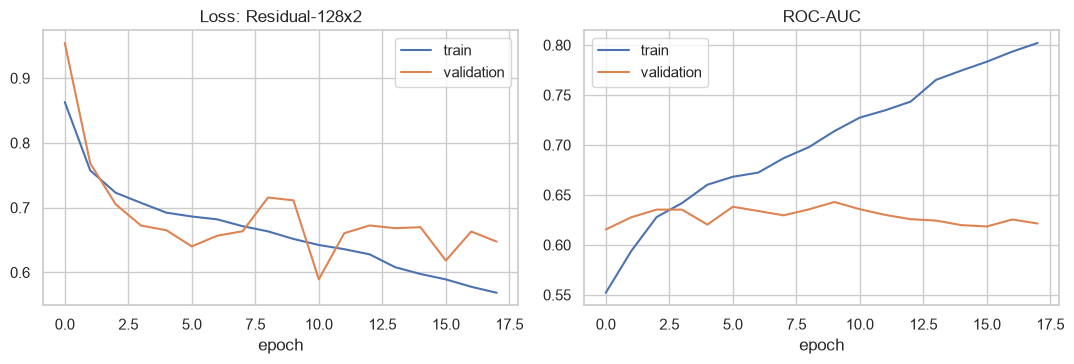

In [28]:
best_dl_name = dl_table.iloc[0]['config']
best_dl, best_hist = dl_runs[best_dl_name]
best_dl.summary()

h = best_hist.history
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='validation')
ax[0].set_title(f'Loss: {best_dl_name}'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h['auc'], label='train'); ax[1].plot(h['val_auc'], label='validation')
ax[1].set_title('ROC-AUC'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

In [29]:
# threshold from validation predictions, then one-time evaluation on the test set
val_proba = best_dl.predict(val_ds, verbose=0).ravel()
dl_thr = best_threshold(yva, val_proba)
dl_test_proba = best_dl.predict(test_ds, verbose=0).ravel()
test_probs['DeepLearning'] = dl_test_proba
thresholds['DeepLearning'] = dl_thr
print('DL threshold: %.3f' % dl_thr)
print('95%% bootstrap CI for ROC-AUC: [%.4f, %.4f]' % tuple(bootstrap_ci(y_test, dl_test_proba)))

DL threshold: 0.386
95% bootstrap CI for ROC-AUC: [0.6362, 0.6695]


## 11. Final comparison: ML vs DL
All models are scored on the same untouched test set. Compare ROC-AUC and PR-AUC (threshold-free), then precision/recall/F-scores at each model's chosen threshold.

In [30]:
final_rows = [summarise(n + (' (tuned)' if n != 'DeepLearning' else f' [{best_dl_name}]'), y_test, test_probs[n], thresholds[n])
              for n in test_probs]
final_summary = pd.DataFrame(final_rows).set_index('model').round(4).sort_values('ROC-AUC', ascending=False)
final_summary

,ROC-AUC,PR-AUC,threshold,precision,recall,F1,F2
model,,,,,,,
RandomForest (tuned),0.6564,0.1792,0.3224,0.1240,0.6794,0.2098,0.3584
DeepLearning [Residual-128x2],0.6518,0.1648,0.3863,0.1081,0.8305,0.1913,0.3555
HistGradientBoosting (tuned),0.6504,0.1832,0.4367,0.1168,0.7001,0.2002,0.3502
LogisticRegression (tuned),0.6486,0.1686,0.4232,0.1143,0.7621,0.1987,0.3571


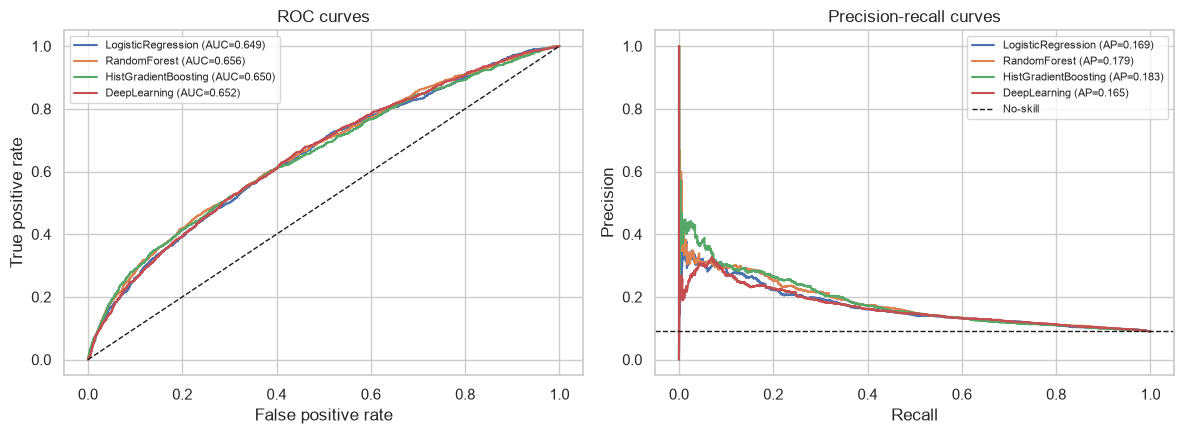

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f'{n} (AUC={roc_auc_score(y_test, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f'{n} (AP={average_precision_score(y_test, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves')
ax[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label='No-skill'); ax[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curves')
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

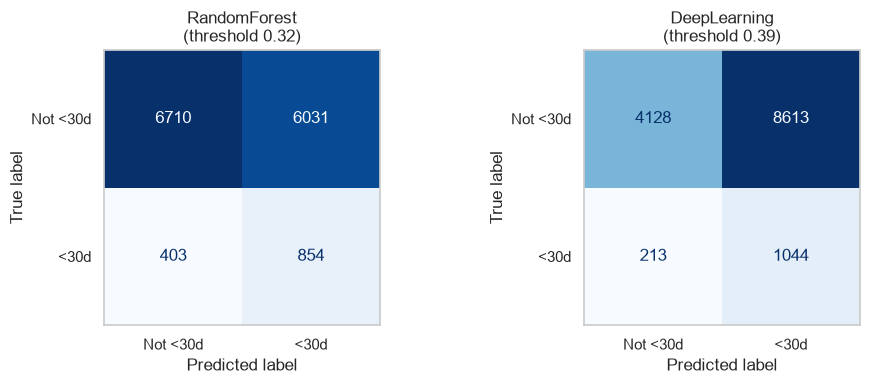

In [32]:
to_plot = [best_name, 'DeepLearning']
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, n in zip(ax, to_plot):
    pred = (test_probs[n] >= thresholds[n]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Not <30d', '<30d'], cmap='Blues', ax=a, colorbar=False)
    a.set_title(f'{n}\n(threshold {thresholds[n]:.2f})'); a.grid(False)
plt.tight_layout(); plt.show()

**Interpretation.** On the same test set the random forest (ROC-AUC 0.6564) is 0.0046 ahead of Residual-128x2 (0.6518). The bootstrap intervals [0.6400, 0.6734] and [0.6362, 0.6695] overlap, so the two paradigms are not separable. Histogram gradient boosting has the highest PR-AUC (0.1832). At the F2 thresholds the forest confusion matrix is 6,710 true negatives, 6,031 false positives, 403 false negatives and 854 true positives. The network is more aggressive: 4,128 true negatives, 8,613 false positives, 213 false negatives and 1,044 true positives.


## 12. Error analysis and feature importance
Good reports go beyond a metrics table. Here we ask:

1. **Who does the model miss?** Recall and false-positive rate per subgroup (age, primary diagnosis, discharge destination).
2. **What drives predictions?** Permutation importance (drop in ROC-AUC when a feature is shuffled) on the best traditional model.

Use these findings in the Discussion: dataset limitations (data from 1999-2008, only 130 hospitals, no socioeconomic or post-discharge data, noisy labels), fairness across subgroups, and why AUC of roughly 0.64-0.68 is typical for this dataset in the literature.

In [33]:
err = X_test.copy()
err['y'] = y_test.values
err['pred'] = (test_probs[best_name] >= thresholds[best_name]).astype(int)

def group_report(col, min_n=150):
    def f(d):
        pos, neg = d[d.y == 1], d[d.y == 0]
        return pd.Series({'n': len(d), 'positives': len(pos),
                          'recall': pos['pred'].mean() if len(pos) else np.nan,
                          'false_pos_rate': neg['pred'].mean() if len(neg) else np.nan})
    out = err.groupby(col).apply(f)
    return out[out['n'] >= min_n].round(3)

for col in ['age', 'diag_1_grp', 'discharge_disposition_id']:
    print(f'--- {col} ---'); display(group_report(col))

--- age ---


,n,positives,recall,false_pos_rate
age,,,,
[20-30),204.0,15.0,0.667,0.212
[30-40),537.0,35.0,0.486,0.197
[40-50),1352.0,94.0,0.468,0.292
[50-60),2466.0,195.0,0.487,0.267
[60-70),3125.0,274.0,0.631,0.453
[70-80),3606.0,378.0,0.775,0.598
[80-90),2239.0,228.0,0.842,0.729
[90-100),331.0,33.0,0.848,0.732


--- diag_1_grp ---


,n,positives,recall,false_pos_rate
diag_1_grp,,,,
Circulatory,4309.0,397.0,0.708,0.535
Diabetes,1083.0,90.0,0.622,0.407
Digestive,1289.0,99.0,0.596,0.427
Genitourinary,670.0,58.0,0.724,0.503
Injury,942.0,112.0,0.839,0.600
Musculoskeletal,851.0,75.0,0.773,0.410
Neoplasms,512.0,53.0,0.623,0.420
Other,2454.0,243.0,0.691,0.472
Respiratory,1885.0,130.0,0.485,0.377


--- discharge_disposition_id ---


,n,positives,recall,false_pos_rate
discharge_disposition_id,,,,
1,8901.0,633.0,0.441,0.278
18,488.0,49.0,0.837,0.702
2,298.0,38.0,0.921,0.762
22,296.0,88.0,1.000,1.000
25,167.0,12.0,0.500,0.490
3,1694.0,229.0,0.969,0.942
5,176.0,34.0,1.000,1.000
6,1681.0,144.0,0.854,0.800


**Interpretation.** Recall rises with age, from 0.468 at ages 40-50 to 0.848 above 90, and the false-positive rate rises with it (0.292 to 0.732). Respiratory primary diagnoses have the lowest recall (0.485); injury has the highest (0.839). Discharge destination is the sharp split. Patients sent home (code 1; 8,901 test rows) have recall 0.441. Patients sent to a skilled nursing facility (code 3) have recall 0.969 and a false-positive rate of 0.942. At this threshold the model largely flags non-home discharges.


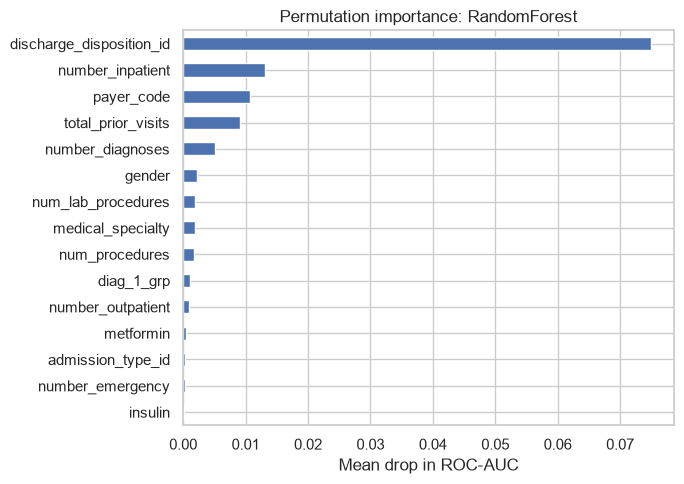

In [34]:
from sklearn.inspection import permutation_importance

feat_cols = NUM + CAT
idx = X_test.sample(6000, random_state=SEED).index
pi = permutation_importance(best_ml, X_test.loc[idx, feat_cols], y_test.loc[idx], scoring='roc_auc',
                            n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=feat_cols).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(figsize=(7, 5), color='#4c72b0')
plt.xlabel('Mean drop in ROC-AUC'); plt.title(f'Permutation importance: {best_name}'); plt.tight_layout(); plt.show()

**Interpretation.** Shuffling discharge disposition drops ROC-AUC by roughly 0.07, about five times the next feature. Prior inpatient visits (about 0.014), payer code (about 0.012) and the engineered total of prior visits (about 0.009) follow. Medication indicators contribute almost nothing. This matches the subgroup table: facility discharges are flagged almost automatically, and patients sent home are often missed.


## 13. Saving artefacts
Saves the best traditional pipeline (preprocessing + model, so it can be used directly on raw rows), the best deep-learning model (`.keras` and `.h5`), the DL preprocessor, and the results tables.
Upload the `artifacts/` folder (and the zipped raw CSV) to your Google Drive folder with sharing set to *Anyone with the link can view*.

On Colab you can copy straight to Drive:
```python
from google.colab import drive; drive.mount('/content/drive')
!cp -r artifacts /content/drive/MyDrive/diabetes_readmission_project/
```

In [35]:
os.makedirs('artifacts', exist_ok=True)
joblib.dump(best_ml, f'artifacts/best_ml_{best_name}.joblib')
joblib.dump(dl_pre, 'artifacts/dl_preprocessor.joblib')
best_dl.save('artifacts/best_dl_model.keras')
best_dl.save('artifacts/best_dl_model.h5')           # legacy format, as requested by the brief
joblib.dump(thresholds, 'artifacts/thresholds.joblib')

baseline_df.to_csv('artifacts/baseline_cv_results.csv', index=False)
dl_table.to_csv('artifacts/dl_experiments.csv', index=False)
final_summary.to_csv('artifacts/final_test_results.csv')
print(os.listdir('artifacts'))

# sanity check: reload and confirm the saved ML model reproduces the test AUC
reloaded = joblib.load(f'artifacts/best_ml_{best_name}.joblib')
print('Reloaded ROC-AUC: %.4f' % roc_auc_score(y_test, reloaded.predict_proba(X_test)[:, 1]))

['baseline_cv_results.csv', 'best_dl_model.h5', 'best_dl_model.keras', 'best_ml_RandomForest.joblib', 'dl_experiments.csv', 'dl_preprocessor.joblib', 'final_test_results.csv', 'thresholds.joblib']
Reloaded ROC-AUC: 0.6564


## Conclusions
The tuned random forest is the best model on the held-out test set, with ROC-AUC **0.6564** (95% bootstrap CI **0.6400-0.6734**) and PR-AUC **0.1792**. The best neural network, Residual-128x2, reaches ROC-AUC **0.6518** (95% CI **0.6362-0.6695**) and PR-AUC **0.1648**. The intervals overlap, so deep learning does not beat the tuned forest on this table. Histogram gradient boosting has the best PR-AUC (**0.1832**).

Feature engineering helps every full-data model, but only by **0.0019 to 0.0058** ROC-AUC (mean **0.0033**). Most of the signal is already in discharge disposition and prior inpatient visits. One engineered feature, `total_prior_visits`, appears in the top four permutation importances; the diagnosis groups and medication summaries do not.

The random-forest learning curve keeps training ROC-AUC near **0.98** while validation ROC-AUC flattens near **0.65**. The network shows the same ceiling: validation AUC peaks at **0.643** while training AUC climbs toward **0.80**, and early stopping fires after **18** epochs. More rows of the same columns, or a deeper network, would not close that gap.

Error analysis shows the operating point is driven by discharge destination. Patients sent home (disposition 1) have recall **0.441**. Patients sent to a skilled nursing facility (disposition 3) are flagged almost always (recall **0.969**, false-positive rate **0.942**). Recall also rises with age, from about **0.47** in middle age to about **0.85** above 80, together with a much higher false-positive rate. The data are from 1999-2008, cover 130 hospitals without a site identifier, contain no social or post-discharge variables, and record only readmissions seen by the source systems. Those limits, not the choice between scikit-learn and Keras, cap performance near a ROC-AUC of 0.65.
